# 1. Project links

# 2. Setup

In [49]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from modules.data_loader import load_data
from modules.mongodb_loader import get_monthly_flow

## 3. Norges Bank Currency API

Norges Bank provides an open REST API for historical exchange-rate data.
For this project, EUR/NOK and USD/NOK exchange rates are downloaded.

The API series follow the structure:

`frequency.base_currency.quote_currency.tenor`

For example:

- `B.EUR.NOK.SP` = daily EUR/NOK spot exchange rate
- `B.USD.NOK.SP` = daily USD/NOK spot exchange rate

The function below accepts currencies and a date interval and returns
the exchange rates in a tidy pandas DataFrame.

### 3.1 Imports og API-adresse

In [50]:
from io import StringIO

import pandas as pd
import requests


NB_API_URL = (
    "https://data.norges-bank.no/api/data/EXR"
)

### 3.2

In [51]:
def download_exchange_rates(
    currencies=("EUR", "USD"),
    start_date="2024-01-01",
    end_date="2024-12-31",
):
    """
    Download daily exchange rates against NOK from
    the Norges Bank open data API.

    Parameters
    ----------
    currencies : tuple or list
        Currency codes to download, e.g. ("EUR", "USD").
    start_date : str
        First date in YYYY-MM-DD format.
    end_date : str
        Last date in YYYY-MM-DD format.

    Returns
    -------
    pd.DataFrame
        DataFrame with date, currency and NOK exchange rate.
    """

    frames = []

    for currency in currencies:

        # Norges Bank series key:
        # B = business-day frequency
        # currency = base currency
        # NOK = quote currency
        # SP = spot rate
        series_key = (
            f"B.{currency}.NOK.SP"
        )

        url = (
            f"{NB_API_URL}/{series_key}"
        )

        params = {
            "format": "csv",
            "startPeriod": start_date,
            "endPeriod": end_date,
            "locale": "en",
        }

        response = requests.get(
            url,
            params=params,
            timeout=60,
        )

        response.raise_for_status()

        # Read the CSV response.
        # sep=None lets pandas detect the delimiter.
        df = pd.read_csv(
            StringIO(response.text),
            sep=None,
            engine="python",
        )

        # Standardise column names.
        df.columns = [
            column.strip().upper()
            for column in df.columns
        ]

        # Check that expected API fields are present.
        required_columns = {
            "TIME_PERIOD",
            "OBS_VALUE",
        }

        if not required_columns.issubset(
            df.columns
        ):
            raise ValueError(
                "Unexpected Norges Bank API response. "
                f"Columns returned: {df.columns.tolist()}"
            )

        exchange_rate = df[
            [
                "TIME_PERIOD",
                "OBS_VALUE",
            ]
        ].copy()

        exchange_rate.columns = [
            "date",
            "exchange_rate",
        ]

        exchange_rate["date"] = (
            pd.to_datetime(
                exchange_rate["date"]
            )
        )

        exchange_rate["exchange_rate"] = (
            pd.to_numeric(
                exchange_rate["exchange_rate"],
                errors="coerce",
            )
        )

        exchange_rate["currency"] = (
            currency
        )

        frames.append(
            exchange_rate
        )

    rates = pd.concat(
        frames,
        ignore_index=True,
    )

    return (
        rates
        .sort_values(
            ["date", "currency"]
        )
        .reset_index(drop=True)
    )

### 3.3 

In [52]:
exchange_rates = download_exchange_rates(
    currencies=["EUR", "USD"],
    start_date="2024-01-01",
    end_date="2024-12-31",
)

display(
    exchange_rates.head(10)
)

print(
    exchange_rates.groupby(
        "currency"
    ).size()
)

,date,exchange_rate,currency
0,2024-01-02,11.2815,EUR
1,2024-01-02,10.2971,USD
2,2024-01-03,11.3200,EUR
3,2024-01-03,10.3672,USD
4,2024-01-04,11.2845,EUR
5,2024-01-04,10.3027,USD
6,2024-01-05,11.3090,EUR
7,2024-01-05,10.3553,USD
8,2024-01-08,11.3620,EUR
9,2024-01-08,10.3800,USD


currency
EUR    251
USD    251
dtype: int64


### 3.4

In [53]:
exchange_rates_wide = (
    exchange_rates
    .pivot(
        index="date",
        columns="currency",
        values="exchange_rate",
    )
    .rename(
        columns={
            "EUR": "eur_nok",
            "USD": "usd_nok",
        }
    )
)

display(
    exchange_rates_wide.head()
)

currency,eur_nok,usd_nok
date,,
2024-01-02,11.2815,10.2971
2024-01-03,11.3200,10.3672
2024-01-04,11.2845,10.3027
2024-01-05,11.3090,10.3553
2024-01-08,11.3620,10.3800


### 3.5

<Axes: title={'center': 'EUR/NOK and USD/NOK Exchange Rates – 2024'}, xlabel='date', ylabel='NOK per unit of currency'>

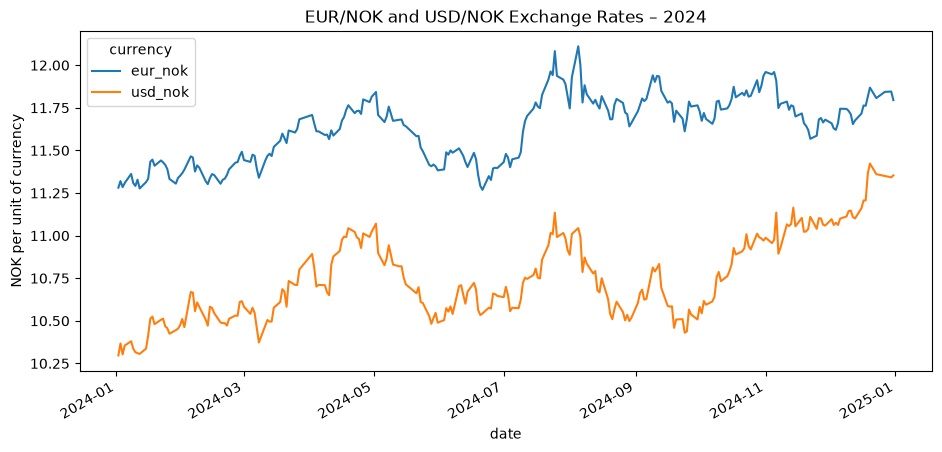

In [54]:
exchange_rates_wide.plot(
    figsize=(11, 5),
    title="EUR/NOK and USD/NOK Exchange Rates – 2024",
    ylabel="NOK per unit of currency",
)

## 4. Timezone Investigation

The project combines data from four different sources:

- NVE Magasinstatistikk
- ENTSO-E Transparency Platform
- Open-Meteo
- Norges Bank

Before combining the datasets, their time representations were investigated
to avoid shifts caused by different time zones or daylight-saving time.

This is particularly important for the hourly ENTSO-E and Open-Meteo data,
while Magasinstatistikk and Norges Bank mainly provide date-based observations.

### 4.1 Findings

| Data source | Time resolution | Time representation | Treatment |
|---|---|---|---|
| Magasinstatistikk | Weekly | Date/week based | Keep as calendar date |
| ENTSO-E | Hourly | UTC | Parse explicitly as UTC |
| Open-Meteo | Hourly | UTC in this project | Parse explicitly as UTC |
| Norges Bank | Daily | Date based | Keep as calendar date |

#### NVE Magasinstatistikk

Magasinstatistikk contains weekly observations. The dates represent
calendar weeks rather than precise timestamps, so timezone conversion
is not required.

For forecasting, the dates can therefore remain timezone-naive and
later be aggregated to monthly observations.

In [55]:
reservoir_data = load_data()

print(
    "Reservoir date dtype:",
    reservoir_data["date"].dtype,
)

print(
    reservoir_data[
        ["date", "area_type", "area_number"]
    ].head()
)

2026-11-23 09:53:56.482 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Reservoir date dtype: datetime64[us]
        date area_type  area_number
0 1995-01-08        EL            1
1 1995-01-08        EL            2
2 1995-01-08        EL            3
3 1995-01-08        EL            4
4 1995-01-08        EL            5


#### ENTSO-E

ENTSO-E API responses express timestamps in UTC. This avoids ambiguity
during changes between CET and CEST.

The MongoDB dataset used in this project therefore stores the physical
flow timestamps as `timestamp_utc`.

When the observations are loaded into pandas, the timestamps should
explicitly be parsed as timezone-aware UTC timestamps.

In [56]:
from modules.mongodb_loader import (
    get_connections,
    get_years,
    get_monthly_flow,
)

# Get one available ENTSO-E connection.
connections = get_connections()
selected_connection = connections[0]

# Use the most recent available year.
years = get_years(selected_connection)
selected_year = years[-1]

# Download one month of data as an example.
entsoe_sample = get_monthly_flow(
    connection=selected_connection,
    year=selected_year,
    months=[1],
)

print("Connection:", selected_connection)
print("Year:", selected_year)
print("Rows:", len(entsoe_sample))

print(
    "Timestamp dtype:",
    entsoe_sample["timestamp_utc"].dtype,
)

print(
    "Timezone:",
    entsoe_sample["timestamp_utc"].dt.tz,
)

display(entsoe_sample.head())

Connection: NO1-SE3
Year: 2026
Rows: 3072
Timestamp dtype: datetime64[us]
Timezone: None


,timestamp_utc,direction,quantity_mw
0,2026-01-01 01:00:00,Import,1180.429722
1,2026-01-01 01:15:00,Import,1229.822714
2,2026-01-01 01:30:00,Import,1315.924619
3,2026-01-01 01:45:00,Import,1584.195592
4,2026-01-01 02:00:00,Import,1392.061410


#### Open-Meteo

Open-Meteo allows the timezone of the returned observations to be
specified explicitly. In this project, all ERA5 requests use
`timezone="UTC"`.

The returned timestamps are therefore parsed explicitly as UTC in
pandas. This makes the Open-Meteo data directly compatible with the
UTC-based ENTSO-E timestamps and avoids ambiguity related to local
time and daylight-saving time.

In [57]:
from modules.weather_analysis import download_weather

weather_sample = download_weather(
    area_type="EL",
    area_number=3,
    start_date="2024-01-01",
    end_date="2024-01-07",
    n_locations=2,
)

print(
    "Open-Meteo timestamp dtype:",
    weather_sample["time"].dtype,
)

print(
    "Timezone:",
    weather_sample["time"].dt.tz,
)

display(weather_sample.head())

Open-Meteo timestamp dtype: datetime64[us, UTC]
Timezone: UTC


,time,avg_temperature,avg_precipitation,avg_snowfall
0,2024-01-01 00:00:00+00:00,-1.35,0.0,0.0
1,2024-01-01 01:00:00+00:00,-1.30,0.0,0.0
2,2024-01-01 02:00:00+00:00,-1.20,0.0,0.0
3,2024-01-01 03:00:00+00:00,-1.20,0.0,0.0
4,2024-01-01 04:00:00+00:00,-1.20,0.0,0.0


#### Norges Bank

Norges Bank publishes daily exchange rates on business days,
normally at approximately 16:00 CET.

The exchange-rate data used in this project are represented by
calendar date rather than an intraday timestamp. Since the data will
later be aggregated to monthly observations for forecasting, no
timezone conversion is required.

The date column is therefore kept as a timezone-naive calendar date.

In [58]:
print(
    "Norges Bank date dtype:",
    exchange_rates["date"].dtype,
)

print(
    exchange_rates[
        ["date", "currency", "exchange_rate"]
    ].head()
)

Norges Bank date dtype: datetime64[us]
        date currency  exchange_rate
0 2024-01-02      EUR        11.2815
1 2024-01-02      USD        10.2971
2 2024-01-03      EUR        11.3200
3 2024-01-03      USD        10.3672
4 2024-01-04      EUR        11.2845


### 4.2 Time Alignment Strategy

The investigation showed that timezone handling is mainly relevant for
the hourly ENTSO-E and Open-Meteo datasets.

Both sources are standardised to timezone-aware UTC timestamps before
further processing.

Magasinstatistikk and Norges Bank use calendar-based observations and
therefore do not require timezone conversion.

For forecasting, all sources will later be aggregated to monthly
observations. This makes it possible to align the datasets by month
while avoiding daylight-saving-time ambiguity in the underlying
hourly data.

## 5. Data Preparation for Forecasting

The forecasting model will use monthly observations.

Reservoir filling level is the target variable. Since Magasinstatistikk
contains weekly observations, the last available filling-level observation
in each month is used to represent the reservoir level at the end of that
month.

Weather data are aggregated as monthly mean temperature and monthly total
precipitation and snowfall. EUR/NOK and USD/NOK are represented by their
monthly mean exchange rates.

Using monthly data reduces the computational cost while preserving the
main seasonal patterns relevant for forecasting reservoir filling levels.

### 5.1 Reservoir target

In [59]:
# Select NO3 from Magasinstatistikk.
reservoir_no3 = (
    reservoir_data[
        (reservoir_data["area_type"] == "EL")
        & (reservoir_data["area_number"] == 3)
    ][["date", "fill_level"]]
    .dropna()
    .sort_values("date")
    .copy()
)

# Use the last weekly observation in each month as
# the representative month-end filling level.
reservoir_monthly = (
    reservoir_no3
    .set_index("date")
    ["fill_level"]
    .resample("ME")
    .last()
    .rename("fill_level")
    .to_frame()
)

display(reservoir_monthly.head())

print(
    "Period:",
    reservoir_monthly.index.min(),
    "to",
    reservoir_monthly.index.max(),
)

print(
    "Monthly observations:",
    len(reservoir_monthly),
)

,fill_level
date,
1995-01-31,0.508148
1995-02-28,0.369497
1995-03-31,0.236923
1995-04-30,0.107109
1995-05-31,0.185751


Period: 1995-01-31 00:00:00 to 2026-11-30 00:00:00
Monthly observations: 383


### 5.2 Weather data

In [60]:
from modules.weather_analysis import download_weather

weather_history = download_weather(
    area_type="EL",
    area_number=3,
    start_date="2020-01-01",
    end_date="2024-12-31",
    n_locations=10,
)

In [61]:
weather_monthly = (
    weather_history
    .set_index("time")
    .resample("ME")
    .agg(
        avg_temperature=(
            "avg_temperature",
            "mean",
        ),
        total_precipitation=(
            "avg_precipitation",
            "sum",
        ),
        total_snowfall=(
            "avg_snowfall",
            "sum",
        ),
    )
)

# The raw Open-Meteo observations are kept as UTC.
# After monthly aggregation, timezone information is no longer
# needed for joining with date-based NVE and Norges Bank data.
weather_monthly.index = (
    weather_monthly.index
    .tz_localize(None)
)

display(weather_monthly.head())

,avg_temperature,total_precipitation,total_snowfall
time,,,
2020-01-31,1.287849,238.34,46.480
2020-02-29,-0.664842,164.75,48.160
2020-03-31,-0.033790,130.16,37.681
2020-04-30,2.072778,134.40,45.766
2020-05-31,3.952352,98.02,22.603


### 5.3 Currency data

In [62]:
currency_monthly = (
    exchange_rates_wide
    .resample("ME")
    .mean()
)

display(currency_monthly.head())

currency,eur_nok,usd_nok
date,,
2024-01-31,11.350086,10.408255
2024-02-29,11.384286,10.546310
2024-03-31,11.512042,10.585689
2024-04-30,11.682800,10.891090
2024-05-31,11.589821,10.719858


In [63]:
exchange_rates = download_exchange_rates(
    currencies=["EUR", "USD"],
    start_date="2020-01-01",
    end_date="2024-12-31",
)

In [64]:
exchange_rates_wide = (
    exchange_rates
    .pivot(
        index="date",
        columns="currency",
        values="exchange_rate",
    )
    .rename(
        columns={
            "EUR": "eur_nok",
            "USD": "usd_nok",
        }
    )
)

currency_monthly = (
    exchange_rates_wide
    .resample("ME")
    .mean()
)

### 5.4 Slå alt sammen

In [65]:
forecast_data = (
    reservoir_monthly
    .join(
        weather_monthly,
        how="inner",
    )
    .join(
        currency_monthly,
        how="inner",
    )
)

display(forecast_data.head())

,fill_level,avg_temperature,total_precipitation,total_snowfall,eur_nok,usd_nok
date,,,,,,
2020-01-31,0.593076,1.287849,238.34,46.480,9.938423,8.953832
2020-02-29,0.501604,-0.664842,164.75,48.160,10.132700,9.291965
2020-03-31,0.334615,-0.033790,130.16,37.681,11.294314,10.220159
2020-04-30,0.263558,2.072778,134.40,45.766,11.342942,10.443505
2020-05-31,0.268268,3.952352,98.02,22.603,10.990579,10.087426


### 5.5 Kontroller manglende verdier

In [66]:
print(
    forecast_data.isna().sum()
)

fill_level             0
avg_temperature        0
total_precipitation    0
total_snowfall         0
eur_nok                0
usd_nok                0
dtype: int64


In [67]:
print(
    forecast_data.describe().round(3)
)

       fill_level  avg_temperature  total_precipitation  total_snowfall  \
count      60.000           60.000               60.000          60.000   
mean        0.609            4.409              124.824          19.165   
std         0.241            5.998               51.144          19.650   
min         0.132           -6.455               42.630           0.000   
25%         0.413           -0.068               86.705           0.371   
50%         0.685            3.031              129.690          13.296   
75%         0.817           10.672              163.260          34.361   
max         0.961           14.473              269.260          80.766   

       eur_nok  usd_nok  
count   60.000   60.000  
mean    10.808    9.786  
std      0.689    0.893  
min      9.624    8.304  
25%     10.164    8.892  
50%     10.721    9.977  
75%     11.467   10.582  
max     11.796   11.199  


In [68]:
print(
    pd.infer_freq(
        forecast_data.index
    )
)

ME


### 5.6 En enkel kontrollplot

array([<Axes: title={'center': 'Monthly Reservoir Filling Level – NO3'}, xlabel='date'>,
       <Axes: title={'center': 'Monthly Mean Temperature – NO3'}, xlabel='date'>],
      dtype=object)

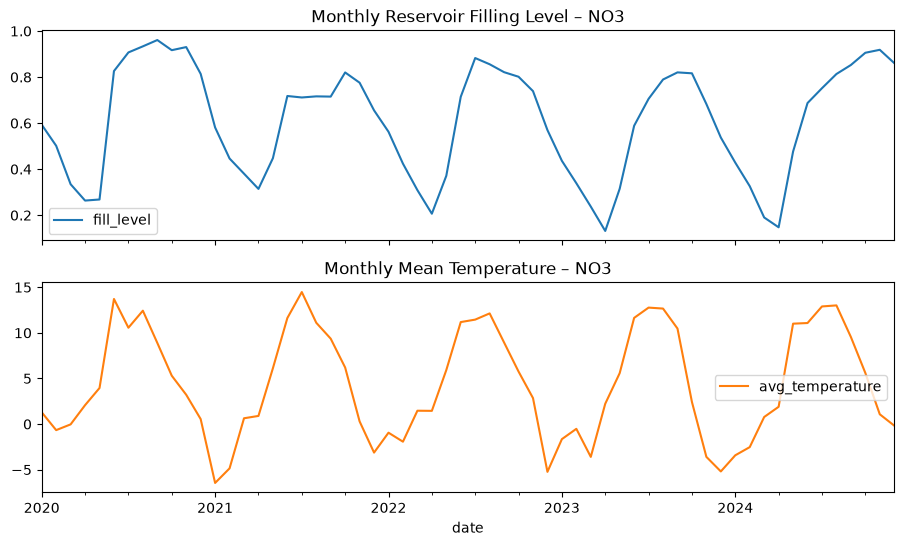

In [69]:
forecast_data[
    [
        "fill_level",
        "avg_temperature",
    ]
].plot(
    subplots=True,
    figsize=(11, 6),
    title=[
        "Monthly Reservoir Filling Level – NO3",
        "Monthly Mean Temperature – NO3",
    ],
)

# 6. River SNARIMAX Forecasting

# 7. Model Testing and Comparison

# 8. Sliding Window Correlation

# 9. Streamlit Structure Sketch

# 10. Streamlit Implementation

# 11. AI Usage

# 12. Work Log